## Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, recall_score, f1_score)

pd.set_option("display.max_columns", 50)


## Loading data

In [ ]:
import pandas as pd, numpy as np

na = ['N/A', 'missing', '--', 'NA', 'null']
rd = lambda f: pd.read_csv(f, na_values=na, keep_default_na=True)

stores    = rd('dim_stores.csv')
skus      = rd('dim_skus.csv')
suppliers = rd('dim_suppliers.csv')
events    = rd('dim_events.csv')
fact      = rd('fact_inventory_daily.csv')

for name, d in [('stores', stores), ('skus', skus), ('suppliers', suppliers),
                ('events', events), ('fact', fact)]:
    print(name, d.shape)

print(fact.stockout_risk.value_counts())
print((fact.stockout_risk.value_counts(normalize=True) * 100).round(2))
print(fact.date.min(), fact.date.max(), fact.date.nunique())
print(fact.lead_time_days_actual.isna().sum())

stores (12, 8)
skus (60, 9)
suppliers (15, 6)
events (30, 5)
fact (21600, 16)
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64
stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64
2026-10-01 2026-10-30 30
19899


## Validating data

In [ ]:
print("stores   :", len(stores))
print("skus     :", len(skus))
print("suppliers:", len(suppliers))
print("events   :", len(events))
print("fact     :", len(fact))

assert len(stores) == 12
assert len(skus) == 60
assert len(suppliers) == 15
assert len(events) == 30
assert len(fact) == 21600
print("Row counts match the spec")

stores   : 12
skus     : 60
suppliers: 15
events   : 30
fact     : 21600
Row counts match the spec


In [ ]:
print(fact["stockout_risk"].value_counts())
print()
print((fact["stockout_risk"].value_counts(normalize=True) * 100).round(2))

vc = fact["stockout_risk"].value_counts()
assert vc["Safe"] == 14131 and vc["At-Risk"] == 5186 and vc["Imminent"] == 2283
print("Target distribution matches the spec")

stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64
Target distribution matches the spec


In [ ]:
print(fact["date"].min(), "to", fact["date"].max())
print("Unique dates:", fact["date"].nunique())
assert fact["date"].min() == "2026-10-01" and fact["date"].max() == "2026-10-30"
assert fact["date"].nunique() == 30

2026-10-01 to 2026-10-30
Unique dates: 30


In [ ]:
miss = fact["lead_time_days_actual"].isna().sum()
print("Missing lead_time_days_actual:", miss, f"({miss/len(fact)*100:.1f}%)")
assert miss == 19899
print("Dates and missing-value count match the spec")

Missing lead_time_days_actual: 19899 (92.1%)
Dates and missing-value count match the spec


In [ ]:
raw = pd.read_csv("dim_suppliers.csv", keep_default_na=False)
print("Raw file (N/A is really there):")
print(raw.loc[raw["reliability_score"] == "N/A", ["supplier_id", "reliability_score"]])

Raw file (N/A is really there):
   supplier_id reliability_score
5        SUP06               N/A
13       SUP14               N/A
14       SUP15               N/A


## Missing-Value Parsing

In [ ]:
print("\nAfter explicit na_values, missing count =", suppliers["reliability_score"].isna().sum())
print(suppliers.loc[suppliers["reliability_score"].isna(), ["supplier_id", "supplier_name", "reliability_score"]])
print("\nColumn dtype:", suppliers["reliability_score"].dtype)


After explicit na_values, missing count = 3
   supplier_id          supplier_name  reliability_score
5        SUP06  QuickBev Distributors                NaN
13       SUP14    Prime Personal Care                NaN
14       SUP15   Regional Produce Hub                NaN

Column dtype: float64


## Cleaning Values

In [ ]:
print("BEFORE:")
print(stores[["store_id", "city", "city_display"]].to_string(index=False))

# Rows where city_display does not match city exactly
print("\nMismatched rows:")
print(stores[stores["city"] != stores["city_display"]][["store_id", "city", "city_display"]])

stores["city_display"] = stores["city_display"].str.title()

print("\nAFTER: mismatches left =", (stores["city"] != stores["city_display"]).sum())

BEFORE:
store_id      city city_display
    ST01    Mumbai       Mumbai
    ST02    Mumbai       Mumbai
    ST03 Bengaluru    BENGALURU
    ST04 Bengaluru    Bengaluru
    ST05     Delhi        Delhi
    ST06     Delhi        Delhi
    ST07      Pune         Pune
    ST08      Pune         Pune
    ST09 Hyderabad    hyderabad
    ST10 Hyderabad    Hyderabad
    ST11   Chennai      Chennai
    ST12   Chennai      Chennai

Mismatched rows:
  store_id       city city_display
2     ST03  Bengaluru    BENGALURU
8     ST09  Hyderabad    hyderabad

AFTER: mismatches left = 0


## Joining all datasets into One Modeling Dataset

In [ ]:
# Check the two supplier_id columns agree before dropping one
check = fact.merge(skus[["sku_id", "supplier_id"]], on="sku_id", suffixes=("", "_sku"))
print("Rows where supplier_id disagrees:", (check["supplier_id"] != check["supplier_id_sku"]).sum())

df = (fact
      .merge(stores, on="store_id", how="left")
      .merge(skus.drop(columns=["supplier_id"]), on="sku_id", how="left")
      .merge(suppliers, on="supplier_id", how="left")
      .merge(events, on="date", how="left"))

print("Shape after joins:", df.shape)
assert len(df) == 21600, "Join changed the row count!"
df["date"] = pd.to_datetime(df["date"])
df.head()

Rows where supplier_id disagrees: 0
Shape after joins: (21600, 39)


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk,city,city_display,city_tier,store_size,sqft,opened_year,baseline_daily_orders,sku_name,category,unit_price_inr,shelf_life_days,is_perishable,festive_relevant,popularity_tier,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


## Festival Week Stockout Risk

In [ ]:
df["is_imminent"] = (df["stockout_risk"] == "Imminent").astype(int)

# 7.1 Festival week effect
fest = (df.groupby("is_festival_week")["is_imminent"].mean() * 100).round(2)
print("Imminent rate by festival flag (%):")
print(fest)
print("Spike:", round(fest["Y"] / fest["N"], 2), "x")

Imminent rate by festival flag (%):
is_festival_week
N     9.51
Y    23.31
Name: is_imminent, dtype: float64
Spike: 2.45 x


## Supplier Reliability

In [ ]:
# 7.2 Supplier reliability effect
# Bands: low < 0.75, mid 0.75-0.85, high >= 0.85.
# The 3 suppliers with 'N/A' reliability are counted in the MID band here -
# that is what reproduces the spec's 6.30% figure.
def rel_band(r):
    if pd.isna(r):
        return "mid (incl. N/A)"
    if r < 0.75:
        return "low (<0.75)"
    if r < 0.85:
        return "mid (incl. N/A)"
    return "high (>=0.85)"

df["rel_band"] = df["reliability_score"].apply(rel_band)
rel = (df.groupby("rel_band")["is_imminent"].mean() * 100).round(2)
print("Imminent rate by supplier reliability (%):")
print(rel)

Imminent rate by supplier reliability (%):
rel_band
high (>=0.85)       3.82
low (<0.75)        15.83
mid (incl. N/A)     6.30
Name: is_imminent, dtype: float64


## Perishable Products

In [ ]:
# 7.3 Perishable effect
per = (df.groupby("is_perishable")["is_imminent"].mean() * 100).round(1)
print("Imminent rate by perishable (%):")
print(per)

Imminent rate by perishable (%):
is_perishable
N     9.3
Y    12.8
Name: is_imminent, dtype: float64


## Visualize the Three Business Signals

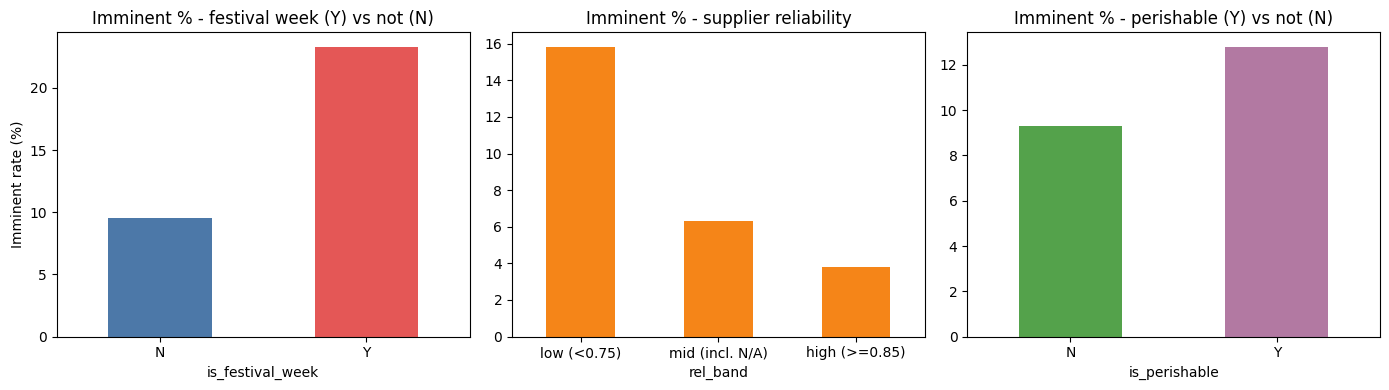

In [ ]:
# charts of the three signals
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

fest.plot(kind="bar", ax=ax[0], color=["#4C78A8", "#E45756"])
ax[0].set_title("Imminent % - festival week (Y) vs not (N)")
ax[0].set_ylabel("Imminent rate (%)")

rel.reindex(["low (<0.75)", "mid (incl. N/A)", "high (>=0.85)"]).plot(kind="bar", ax=ax[1], color="#F58518")
ax[1].set_title("Imminent % - supplier reliability")

per.plot(kind="bar", ax=ax[2], color=["#54A24B", "#B279A2"])
ax[2].set_title("Imminent % - perishable (Y) vs not (N)")

for a in ax:
    a.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## Stock and Supplier Features

In [ ]:
# Sort so that "previous days" are really the previous days for each store+SKU pair
df = df.sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True)

# 8.1 reorder_gap
df["reorder_gap"] = df["reorder_point"] - df["closing_stock"]

# 8.2 days_of_cover_ratio
df["days_of_cover_ratio"] = df["days_of_cover"] / df["lead_time_days_expected"]

# 8.3 supplier_reliability_clean : fill NaN with the median reliability of that SKU category
cat_median = df.groupby("category")["reliability_score"].transform("median")
df["supplier_reliability_clean"] = df["reliability_score"].fillna(cat_median)
print("Missing after imputation:", df["supplier_reliability_clean"].isna().sum())

Missing after imputation: 0


## Recent Reorder Flag

In [ ]:
# 8.4 is_recent_reorder : was a reorder placed in the previous N days for this store+SKU?
N = 3
df["reorder_flag"] = (df["reorder_placed"] == "Y").astype(int)
df["is_recent_reorder"] = (
    df.groupby(["store_id", "sku_id"])["reorder_flag"]
      .transform(lambda s: s.shift(1).rolling(N, min_periods=1).max())
      .fillna(0)
      .astype(int)
)

## Calendar Variables

In [ ]:
# 8.5 temporal features
df["day_of_month"] = df["date"].dt.day
df["days_since_festival_start"] = (df["date"] - pd.Timestamp("2026-10-22")).dt.days

df[["reorder_gap", "days_of_cover_ratio", "supplier_reliability_clean",
    "is_recent_reorder", "day_of_month", "days_since_festival_start"]].describe().round(2)

,reorder_gap,days_of_cover_ratio,supplier_reliability_clean,is_recent_reorder,day_of_month,days_since_festival_start
count,21600.00,21600.00,21600.00,21600.00,21600.00,21600.00
mean,-53.54,4.70,0.76,0.22,15.50,-6.50
std,104.71,4.49,0.11,0.41,8.66,8.66
min,-810.00,0.00,0.63,0.00,1.00,-21.00
25%,-78.50,1.63,0.69,0.00,8.00,-14.00
50%,-26.30,3.14,0.70,0.00,15.50,-6.50
75%,0.00,6.48,0.91,0.00,23.00,1.00
max,393.50,134.85,0.93,1.00,30.00,8.00


## Model Features and Target

In [ ]:
df["demand_multiplier_applied"] = np.where(df["festive_relevant"] == "Y",
                                           df["demand_multiplier_festive"],
                                           df["demand_multiplier_other"])

for c in ["is_perishable", "festive_relevant", "is_festival_week"]:
    df[c + "_num"] = (df[c] == "Y").astype(int)

df["popularity_num"] = df["popularity_tier"].map({"Low": 0, "Medium": 1, "High": 2})
df["store_size_num"] = df["store_size"].map({"Small": 0, "Medium": 1, "Large": 2})

numeric_features = [
    "opening_stock", "closing_stock", "units_demanded", "units_sold",
    "reorder_point", "lead_time_days_expected", "sales_velocity_7d", "days_of_cover",
    "reorder_gap", "days_of_cover_ratio", "is_recent_reorder",
    "day_of_month", "days_since_festival_start",
    "unit_price_inr", "shelf_life_days",
    "is_perishable_num", "festive_relevant_num", "is_festival_week_num",
    "popularity_num", "store_size_num", "sqft", "baseline_daily_orders",
    "base_lead_time_days", "lead_time_variance_days", "supplier_reliability_clean",
    "demand_multiplier_applied",
]

X = pd.concat([df[numeric_features],
               pd.get_dummies(df["category"], prefix="cat", dtype=int)], axis=1)
y = df["stockout_risk"]

print("X shape:", X.shape)
print("Any missing values in X:", X.isna().any().any())

X shape: (21600, 34)
Any missing values in X: False


## Time Based Train/Test Split

In [ ]:
train_mask = df["date"] <= pd.Timestamp("2026-10-23")
test_mask  = ~train_mask

X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("\nTrain class share:\n", (y_train.value_counts(normalize=True) * 100).round(1))
print("\nTest class share:\n", (y_test.value_counts(normalize=True) * 100).round(1))

Train rows: 16560 | Test rows: 5040

Train class share:
 stockout_risk
Safe        66.4
At-Risk     24.5
Imminent     9.1
Name: proportion, dtype: float64

Test class share:
 stockout_risk
Safe        62.3
At-Risk     22.3
Imminent    15.4
Name: proportion, dtype: float64


## Model Evaluation Function

In [ ]:
labels = ["Safe", "At-Risk", "Imminent"]
results = []

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    imm_recall = recall_score(y_test, pred, labels=["Imminent"], average=None)[0]
    macro_f1 = f1_score(y_test, pred, average="macro")
    results.append({"Model": name, "Accuracy": round(acc, 4),
                    "Imminent Recall": round(imm_recall, 4), "Macro F1": round(macro_f1, 4)})

    print("=" * 60, "\n", name, "\n", "=" * 60)
    print(classification_report(y_test, pred, labels=labels, zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=labels)
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(pd.DataFrame(cm, index=labels, columns=labels))
    return model

## Training

In [ ]:
baseline = evaluate("Baseline (majority class)", DummyClassifier(strategy="most_frequent"))

 Baseline (majority class) 
              precision    recall  f1-score   support

        Safe       0.62      1.00      0.77      3139
     At-Risk       0.00      0.00      0.00      1126
    Imminent       0.00      0.00      0.00       775

    accuracy                           0.62      5040
   macro avg       0.21      0.33      0.26      5040
weighted avg       0.39      0.62      0.48      5040

Confusion matrix (rows = actual, columns = predicted):
          Safe  At-Risk  Imminent
Safe      3139        0         0
At-Risk   1126        0         0
Imminent   775        0         0


## Training Logistic Regression

In [ ]:
logreg = evaluate("Logistic Regression",
                  make_pipeline(StandardScaler(),
                                LogisticRegression(max_iter=2000, random_state=42)))

 Logistic Regression 
              precision    recall  f1-score   support

        Safe       0.98      1.00      0.99      3139
     At-Risk       0.85      0.82      0.83      1126
    Imminent       0.81      0.80      0.80       775

    accuracy                           0.93      5040
   macro avg       0.88      0.87      0.87      5040
weighted avg       0.92      0.93      0.92      5040

Confusion matrix (rows = actual, columns = predicted):
          Safe  At-Risk  Imminent
Safe      3130        9         0
At-Risk     65      919       142
Imminent     0      158       617


## Training Random Forest

In [ ]:
rf = evaluate("Random Forest",
              RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))

 Random Forest 
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.81      0.95      0.87      1126
    Imminent       0.90      0.67      0.77       775

    accuracy                           0.94      5040
   macro avg       0.90      0.87      0.88      5040
weighted avg       0.94      0.94      0.94      5040

Confusion matrix (rows = actual, columns = predicted):
          Safe  At-Risk  Imminent
Safe      3135        4         0
At-Risk      2     1069        55
Imminent     0      252       523


## Training Gradient Boosting



In [ ]:
gb = evaluate("Gradient Boosting", GradientBoostingClassifier(random_state=42))

 Gradient Boosting 
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.85      0.94      0.89      1126
    Imminent       0.90      0.75      0.82       775

    accuracy                           0.95      5040
   macro avg       0.92      0.90      0.90      5040
weighted avg       0.95      0.95      0.95      5040

Confusion matrix (rows = actual, columns = predicted):
          Safe  At-Risk  Imminent
Safe      3137        2         0
At-Risk      0     1061        65
Imminent     0      192       583


## Comparing Model

In [ ]:
results_df = pd.DataFrame(results).set_index("Model")
results_df

,Accuracy,Imminent Recall,Macro F1
Model,,,
Baseline (majority class),0.6228,0.0000,0.2559
Logistic Regression,0.9258,0.7961,0.8746
Random Forest,0.9379,0.6748,0.8815
Gradient Boosting,0.9486,0.7523,0.9034


## Plotting the Model Comparison

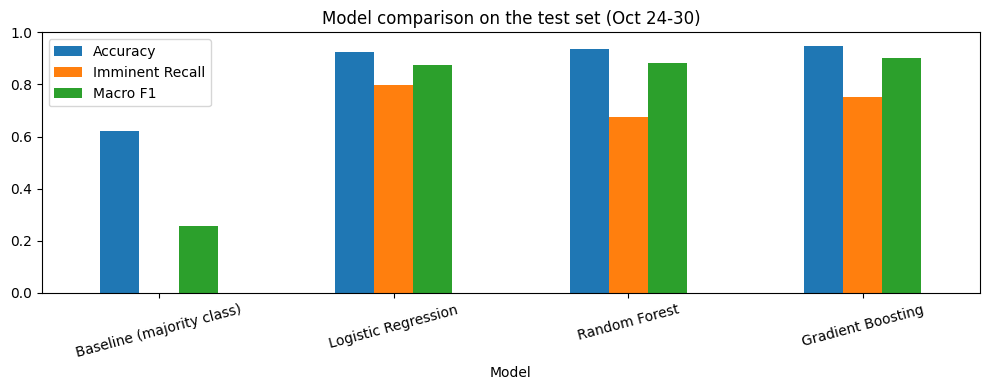

In [ ]:
ax = results_df.plot(kind="bar", figsize=(10, 4), rot=15)
ax.set_title("Model comparison on the test set (Oct 24-30)")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## Inspecting Tree Model Feature

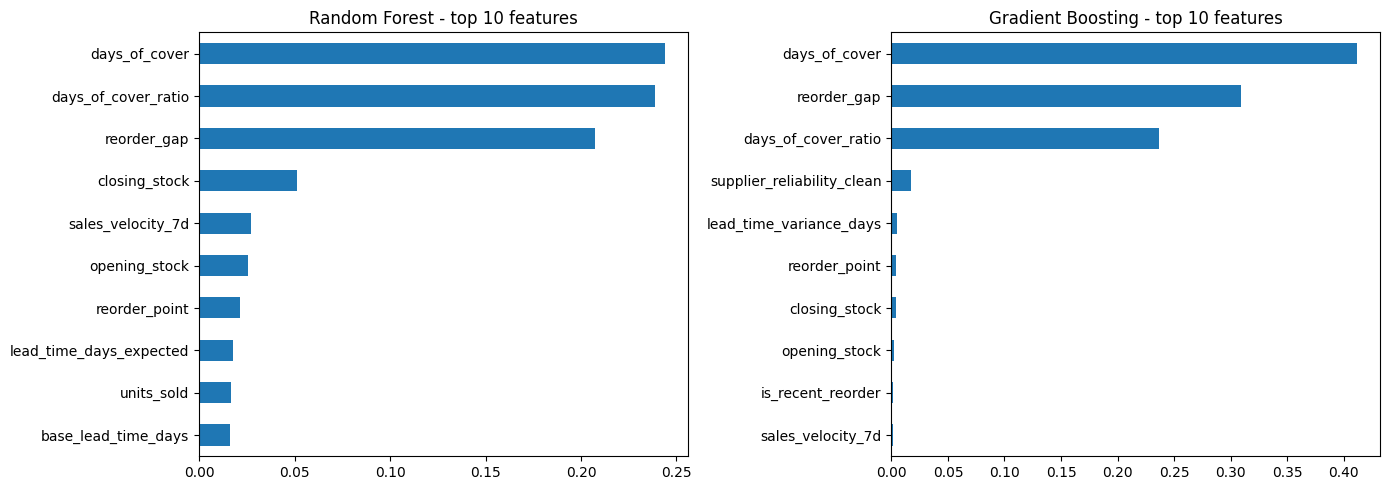

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(10).plot(kind="barh", ax=ax[0])
ax[0].set_title("Random Forest - top 10 features")

pd.Series(gb.feature_importances_, index=X.columns).sort_values().tail(10).plot(kind="barh", ax=ax[1])
ax[1].set_title("Gradient Boosting - top 10 features")

plt.tight_layout()
plt.show()

## Inspecting Logistic Regression Coefficients

In [ ]:
lr_model = logreg.named_steps["logisticregression"]
imm_idx = list(lr_model.classes_).index("Imminent")

coef = pd.Series(lr_model.coef_[imm_idx], index=X.columns).sort_values()
print("Most negative (push AWAY from Imminent):")
print(coef.head(5).round(3))
print("\nMost positive (push TOWARD Imminent):")
print(coef.tail(5).round(3))

Most negative (push AWAY from Imminent):
days_of_cover_ratio          -6.881
days_of_cover                -6.488
units_sold                   -0.893
supplier_reliability_clean   -0.874
opening_stock                -0.686
dtype: float64

Most positive (push TOWARD Imminent):
reorder_gap                0.409
lead_time_days_expected    0.545
base_lead_time_days        0.545
sales_velocity_7d          0.726
units_demanded             1.246
dtype: float64


## Leakage Check (Remove Days of Cover Features)


In [ ]:
X2 = X.drop(columns=["days_of_cover", "days_of_cover_ratio"])
rf2 = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X2[train_mask], y_train)
pred2 = rf2.predict(X2[test_mask])

print("RF without days_of_cover features")
print("Accuracy       :", round(accuracy_score(y_test, pred2), 4))
print("Imminent recall:", round(recall_score(y_test, pred2, labels=["Imminent"], average=None)[0], 4))

RF without days_of_cover features
Accuracy       : 0.8427
Imminent recall: 0.6013




```
======================================================================================
                         QUICKCART INVENTORY ANALYTICS PROJECT
                      AI-POWERED STOCKOUT RISK PREDICTION
                    21,600 INVENTORY RECORDS | OCTOBER 2026
======================================================================================


--------------------------------------------------------------------------------------
EXECUTIVE SUMMARY
======================================================================================

Inventory Records                  : 21,600
Stores Analysed                    : 12
Product SKUs                        : 60
Suppliers                           : 15
Observation Period                  : 01 October 2026 - 30 October 2026
Total Observation Days              : 30
Safe Inventory Records              : 14,131 (65.42%)
At-Risk Inventory Records           : 5,186 (24.01%)
Imminent Stockout Records           : 2,283 (10.57%)
Missing Actual Lead-Time Values     : 19,899 (92.1%)
Machine Learning Models Evaluated   : 4
Training Records                    : 16,560
Testing Records                     : 5,040


--------------------------------------------------------------------------------------
INVENTORY RISK ANALYSIS
======================================================================================

Safe Inventory                      : 65.42%
At-Risk Inventory                   : 24.01%
Imminent Stockout Risk              : 10.57%

Key Findings:

Festival-Week Imminent Risk          : 23.31%
Non-Festival Imminent Risk           : 9.51%
Festival Risk Increase               : 2.45x

Low-Reliability Supplier Risk        : 15.83%
Medium-Reliability Supplier Risk     : 6.30%
High-Reliability Supplier Risk       : 3.82%

Perishable Product Risk              : 12.80%
Non-Perishable Product Risk          : 9.30%


--------------------------------------------------------------------------------------
MACHINE LEARNING MODEL PERFORMANCE
======================================================================================

Model                         Accuracy    Imminent Recall    Macro F1
--------------------------------------------------------------------------------------
Baseline (Majority Class)      62.28%          0.00%          0.2559
Logistic Regression            92.58%         79.61%          0.8746
Random Forest                  93.79%         67.48%          0.8815
Gradient Boosting              94.86%         75.23%          0.9034
--------------------------------------------------------------------------------------

BEST MODEL BY OVERALL ACCURACY  : Gradient Boosting
HIGHEST IMMINENT-CLASS RECALL   : Logistic Regression
BEST MACRO F1 SCORE             : Gradient Boosting

Gradient Boosting achieved the highest overall accuracy of 94.86%
and the highest Macro F1 score of 0.9034.

Logistic Regression achieved the highest imminent-stockout recall
of 79.61%, making it an important candidate when identifying
potential stockouts is the primary business priority.


--------------------------------------------------------------------------------------
KEY BUSINESS INSIGHTS
======================================================================================

1. FESTIVAL DEMAND IMPACT

   Imminent stockout risk increased from 9.51% on non-festival
   days to 23.31% during festival week.

   Business implication:
   Inventory planning should account for increased demand during
   festival periods, especially for festival-relevant products.


2. SUPPLIER RELIABILITY

   Low-reliability suppliers showed a 15.83% imminent-risk rate,
   compared with 3.82% for high-reliability suppliers.

   Business implication:
   Supplier reliability and delivery performance should be
   monitored to reduce replenishment delays and stockout exposure.


3. PERISHABLE PRODUCT RISK

   Perishable products showed a 12.80% imminent-risk rate,
   compared with 9.30% for non-perishable products.

   Business implication:
   Perishable inventory requires closer monitoring to balance
   product availability, replenishment and wastage.


4. INVENTORY AND DEMAND SIGNALS

   Logistic Regression coefficients indicate that higher demand,
   higher seven-day sales velocity and longer expected lead times
   are associated with greater imminent-stockout risk.

   Business implication:
   Demand patterns, supplier lead times and inventory coverage
   should be considered together when prioritising stock alerts.


--------------------------------------------------------------------------------------
EXECUTIVE-LEVEL RECOMMENDATIONS
======================================================================================

1. STRENGTHEN FESTIVAL INVENTORY PLANNING

   Prepare replenishment plans before festival demand peaks.
   Prioritise products with higher expected demand and limited
   inventory coverage.


2. IMPROVE SUPPLIER PERFORMANCE

   Review suppliers with lower reliability scores.
   Monitor delivery delays and establish alternative sourcing
   arrangements for critical products where feasible.


3. PRIORITISE HIGH-RISK PRODUCTS

   Use stockout risk classifications to identify products needing
   immediate review, particularly perishable products and items
   with high sales velocity.


4. SELECT THE MODEL BASED ON BUSINESS OBJECTIVES

   Gradient Boosting is the strongest model by overall accuracy
   and Macro F1 score.

   Logistic Regression has the highest imminent-class recall.
   The final choice should consider missed-stockout costs,
   unnecessary alerts and the operational capacity to respond.


5. IMPROVE DATA QUALITY

   Actual lead-time data are missing in 92.1% of records.
   Improve supplier delivery data collection and validation
   before using the system for live operational decisions.


--------------------------------------------------------------------------------------
MODEL VALIDATION AND LIMITATIONS
======================================================================================

Dataset Period                    : 01-30 October 2026
Training Period                   : 01-23 October 2026
Testing Period                    : 24-30 October 2026
Training Records                  : 16,560
Testing Records                   : 5,040
Validation Approach               : Time-Based Train/Test Split
Models Evaluated                  : Baseline, Logistic Regression,
                                    Random Forest, Gradient Boosting

Leakage Sensitivity Check:
Random Forest without days-of-cover features:
Accuracy                          : 84.27%
Imminent-Class Recall              : 60.13%

Important Limitations:

- The dataset covers only 30 days.
- Actual lead-time values are missing for 92.1% of records.
- Performance may change across different seasons and demand cycles.
- Further validation is needed to confirm generalisation.
- Operational deployment requires additional testing for data
  leakage, alert precision and real-world stockout costs.


--------------------------------------------------------------------------------------
FINAL CONCLUSION
======================================================================================

The QuickCart Stockout Risk Prediction project demonstrates how
inventory data and machine learning can help identify products
that may face stock shortages.

The analysis highlights festival demand, supplier reliability
and product perishability as important inventory risk signals.

Among the evaluated models, Gradient Boosting achieved the best
overall accuracy and Macro F1 score, while Logistic Regression
achieved the highest recall for imminent stockouts.

The findings can support more informed replenishment planning,
supplier monitoring and risk-based inventory management.

Further data-quality improvements and validation across longer
periods are recommended before operational deployment.


======================================================================================
                         END OF FINAL PROJECT REPORT
======================================================================================
```

